# Movie Review Sentiment Analysis using LSTM (TensorFlow)

**Course:** Deep Learning  |  **Task:** Binary text classification (positive / negative)  |  **Framework:** TensorFlow / Keras

## Objective
Build a deep learning model that reads a movie review and predicts whether the sentiment is **positive** or **negative**.

## Why LSTM?
Text is sequential: the meaning of a word depends on the words around it ("not good" vs "good"). A plain feed-forward network ignores word order, and a vanilla RNN struggles to remember information over long sequences because of vanishing gradients. **Long Short-Term Memory (LSTM)** networks use gates (input, forget, output) and a cell state to selectively remember or forget information, which makes them well suited to long reviews.

## Dataset
**IMDB Movie Reviews** (Maas et al., 2011), bundled with Keras: 50,000 labelled reviews, 25,000 for training and 25,000 for testing, perfectly balanced between positive and negative. Reviews are already converted to sequences of integer word indices.

## Pipeline
1. Setup and imports
2. Load the dataset
3. Exploratory data analysis (EDA)
4. Preprocessing (padding, train/validation split)
5. Model building (Embedding → Bidirectional LSTM → Dense)
6. Training with callbacks
7. Training curves
8. Evaluation on the test set
9. Error analysis
10. Predicting on custom reviews
11. Saving the model
12. Conclusion and future work

## 1. Setup and Imports

We import the libraries we need and fix random seeds so results are reproducible. All hyperparameters live in one `CONFIG` dictionary so they are easy to find and tune later.

In [16]:
!pip install pandas seaborn tensorflow

In [1]:
import os
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, accuracy_score)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

CONFIG = {
    "vocab_size": 10000,    # keep only the 10,000 most frequent words
    "max_len": 256,         # every review is padded / truncated to this length
    "embedding_dim": 128,   # size of each word vector
    "lstm_units": 64,       # hidden units in each LSTM direction
    "dropout": 0.5,
    "batch_size": 128,
    "epochs": 15,
    "learning_rate": 1e-3,
    "val_split": 0.2,
}
sns.set_style("whitegrid")
CONFIG

{'vocab_size': 10000,
 'max_len': 256,
 'embedding_dim': 128,
 'lstm_units': 64,
 'dropout': 0.5,
 'batch_size': 128,
 'epochs': 15,
 'learning_rate': 0.001,
 'val_split': 0.2}

## 2. Load the Dataset

`imdb.load_data(num_words=10000)` returns reviews as lists of integers. Words are ranked by frequency, so index `1` is not "the" but a special token. Keras reserves:

| Index | Meaning |
|-------|---------|
| 0 | `<PAD>` (padding) |
| 1 | `<START>` (start of review) |
| 2 | `<UNK>` (unknown / out-of-vocabulary word) |
| 3+ | actual words, shifted by 3 |

Any word outside the top 10,000 is replaced with `<UNK>`, which keeps the vocabulary small and the model fast.

In [3]:
(x_train_full, y_train_full), (x_test, y_test) = imdb.load_data(num_words=CONFIG["vocab_size"])

print("Training reviews:", len(x_train_full))
print("Test reviews    :", len(x_test))
print("First review (integer encoded):", x_train_full[0][:20], "...")
print("Label of first review:", y_train_full[0], "(1 = positive, 0 = negative)")

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Training reviews: 25000
Test reviews    : 25000
First review (integer encoded): [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25] ...
Label of first review: 1 (1 = positive, 0 = negative)


### Decoding reviews back to text
To understand the data, we build a reverse dictionary (index → word) and decode a few reviews. We shift the word index by 3 to account for the reserved tokens.

In [4]:
word_index = imdb.get_word_index()
word_index = {w: (i + 3) for w, i in word_index.items()}
word_index["<PAD>"], word_index["<START>"], word_index["<UNK>"] = 0, 1, 2
reverse_word_index = {i: w for w, i in word_index.items()}

def decode_review(seq):
    return " ".join(reverse_word_index.get(i, "?") for i in seq)

for i in range(2):
    label = "Positive" if y_train_full[i] == 1 else "Negative"
    print(f"[{label}] {decode_review(x_train_full[i])[:400]}...\n")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
[Positive] <START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it...

[Negative] <START> big hair big boobs bad music and a giant safety pin these are the words to best describe this terrible movie i love cheesy horror movies and i've seen hundreds but this had got to be on of the worst ever made the plot is paper thin and ridiculous the acting is an abomination the script is completely laughable the best is the end showdown with the cop and how he worked out who the killer is...



## 3. Exploratory Data Analysis

Before modelling, we check two things that influence design decisions:

1. **Class balance** — if one class dominates, accuracy alone would be misleading.
2. **Review length** — this determines the padding length (`max_len`). Too short loses information; too long wastes computation.

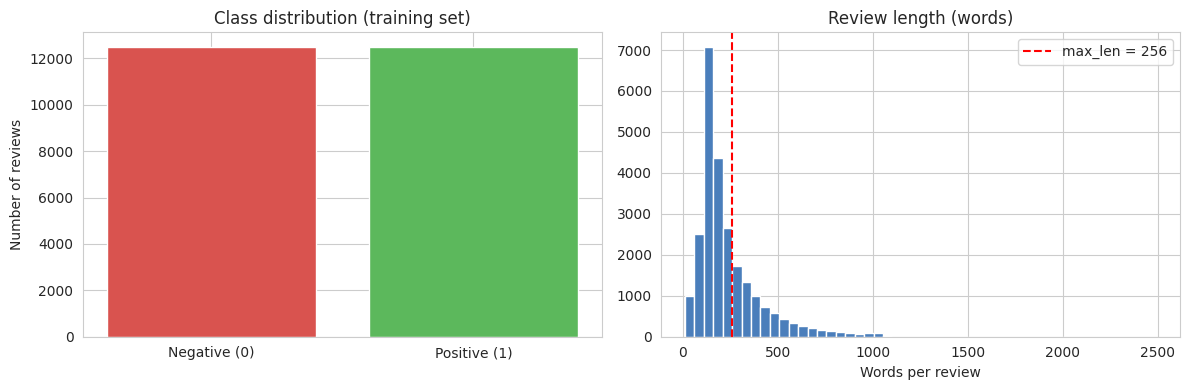

Mean length  : 238.7
Median length: 178.0
95th pct     : 610
Reviews longer than max_len: 30.1%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Class balance
counts = pd.Series(y_train_full).value_counts().sort_index()
axes[0].bar(["Negative (0)", "Positive (1)"], counts.values, color=["#d9534f", "#5cb85c"])
axes[0].set_title("Class distribution (training set)")
axes[0].set_ylabel("Number of reviews")

# Review length
lengths = [len(r) for r in x_train_full]
axes[1].hist(lengths, bins=50, color="#4a7ebb")
axes[1].axvline(CONFIG["max_len"], color="red", linestyle="--", label=f"max_len = {CONFIG['max_len']}")
axes[1].set_title("Review length (words)")
axes[1].set_xlabel("Words per review")
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Mean length  : {np.mean(lengths):.1f}")
print(f"Median length: {np.median(lengths):.1f}")
print(f"95th pct     : {np.percentile(lengths, 95):.0f}")
print(f"Reviews longer than max_len: {np.mean(np.array(lengths) > CONFIG['max_len']) * 100:.1f}%")

**Observations**

- The classes are balanced (50/50), so **accuracy** is a fair headline metric.
- Most reviews are shorter than a few hundred words. A `max_len` of 256 covers the majority of reviews fully while keeping training fast; longer reviews are truncated.

## 4. Preprocessing

### 4.1 Padding and truncation
Neural networks need fixed-size inputs, but reviews have different lengths. We:
- **pad** short reviews with zeros, and
- **truncate** long reviews to `max_len`.

We use `padding='post'` (zeros at the end) so the Embedding layer's masking works efficiently with the LSTM on GPU (cuDNN requires right-padded sequences when masks are used).

In [6]:
x_train_full = pad_sequences(x_train_full, maxlen=CONFIG["max_len"], padding="post", truncating="post")
x_test       = pad_sequences(x_test,       maxlen=CONFIG["max_len"], padding="post", truncating="post")

print("Padded training shape:", x_train_full.shape)
print("Padded test shape    :", x_test.shape)
print("Example padded review (last 15 tokens):", x_train_full[0][-15:])

Padded training shape: (25000, 256)
Padded test shape    : (25000, 256)
Example padded review (last 15 tokens): [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


### 4.2 Train / validation split
The test set is kept untouched until the very end. We carve a **validation set** (20%) out of the training data to monitor overfitting and drive early stopping. We use `stratify` so both sets keep the same class balance.

In [7]:
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full,
    test_size=CONFIG["val_split"],
    stratify=y_train_full,
    random_state=SEED,
)

print(f"Train: {x_train.shape[0]:,}  |  Validation: {x_val.shape[0]:,}  |  Test: {x_test.shape[0]:,}")

Train: 20,000  |  Validation: 5,000  |  Test: 25,000


## 5. Model Architecture

| Layer | Purpose |
|-------|---------|
| **Embedding** | Turns each word index into a dense, learnable vector (128-d). Similar words end up with similar vectors. `mask_zero=True` makes the network ignore padding. |
| **Bidirectional LSTM** | Reads the review forwards *and* backwards, so each position has context from both sides. Outputs a single vector summarising the review. |
| **Dropout** | Randomly zeroes 50% of activations during training to reduce overfitting. |
| **Dense (ReLU)** | A small fully connected layer to combine LSTM features. |
| **Dense (Sigmoid)** | Outputs a probability between 0 and 1 (closer to 1 = positive). |

**Loss:** binary cross-entropy (two classes). **Optimizer:** Adam. **Metric:** accuracy.

In [8]:
def build_model(cfg):
    model = keras.Sequential([
        layers.Input(shape=(cfg["max_len"],)),
        layers.Embedding(cfg["vocab_size"], cfg["embedding_dim"], mask_zero=True, name="embedding"),
        layers.Bidirectional(layers.LSTM(cfg["lstm_units"]), name="bi_lstm"),
        layers.Dropout(cfg["dropout"]),
        layers.Dense(32, activation="relu"),
        layers.Dropout(cfg["dropout"]),
        layers.Dense(1, activation="sigmoid", name="output"),
    ], name="lstm_sentiment")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=cfg["learning_rate"]),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return model

model = build_model(CONFIG)
model.summary()

Model: "lstm_sentiment"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 256, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bi_lstm (Bidirectional)         │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,382,977 (5.28 MB)

 Trainable params: 1,382,977 (5.28 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Training

We use three **callbacks** to make training smarter:

- **EarlyStopping** — stops when validation loss stops improving (patience = 3) and restores the best weights, preventing overfitting.
- **ModelCheckpoint** — saves the best model seen so far to disk.
- **ReduceLROnPlateau** — halves the learning rate when validation loss plateaus, helping the model settle into a better minimum.

In [9]:
os.makedirs("models", exist_ok=True)

callbacks = [
    EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=1),
    ModelCheckpoint("models/best_lstm_sentiment.keras", monitor="val_loss", save_best_only=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-5, verbose=1),
]

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=CONFIG["epochs"],
    batch_size=CONFIG["batch_size"],
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.6254 - loss: 0.6188
Epoch 1: val_loss improved from None to 0.41441, saving model to models/best_lstm_sentiment.keras

Epoch 1: finished saving model to models/best_lstm_sentiment.keras
157/157 ━━━━━━━━━━━━━━━━━━━━ 16s 62ms/step - accuracy: 0.7377 - loss: 0.5127 - val_accuracy: 0.8108 - val_loss: 0.4144 - learning_rate: 0.0010
Epoch 2/15
157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.8831 - loss: 0.3075
Epoch 2: val_loss improved from 0.41441 to 0.33582, saving model to models/best_lstm_sentiment.keras

Epoch 2: finished saving model to models/best_lstm_sentiment.keras
157/157 ━━━━━━━━━━━━━━━━━━━━ 11s 67ms/step - accuracy: 0.8993 - loss: 0.2695 - val_accuracy: 0.8572 - val_loss: 0.3358 - learning_rate: 0.0010
Epoch 3/15
155/157 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9191 - loss: 0.2304
Epoch 3: val_loss did not improve from 0.33582

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.000500000023748

## 7. Training Curves

Plotting loss and accuracy per epoch shows how well the model is learning:
- If **training accuracy keeps rising while validation accuracy flattens or drops**, the model is overfitting.
- If both are low, the model is underfitting.

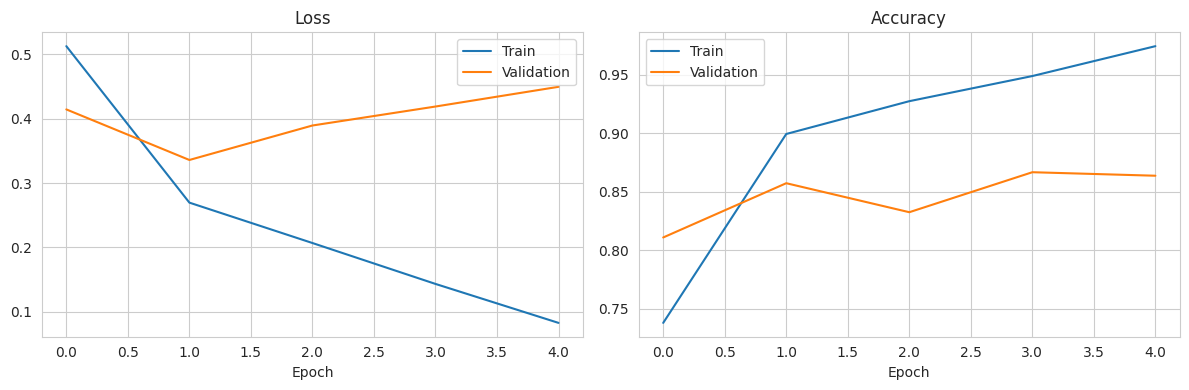

In [10]:
hist = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(hist["loss"], label="Train")
axes[0].plot(hist["val_loss"], label="Validation")
axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend()

axes[1].plot(hist["accuracy"], label="Train")
axes[1].plot(hist["val_accuracy"], label="Validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("Epoch"); axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Evaluation on the Test Set

Now we use the held-out test set (never seen during training or tuning) for an honest estimate of real-world performance. Besides accuracy we report:

- **Precision / Recall / F1** per class
- **Confusion matrix** — where the model gets confused
- **ROC curve and AUC** — how well the model separates the two classes across all thresholds

In [11]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test loss    : {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

y_prob = model.predict(x_test, batch_size=256, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("\nClassification report:\n")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"], digits=4))

Test loss    : 0.3440
Test accuracy: 0.8495

Classification report:

              precision    recall  f1-score   support

    Negative     0.8068    0.9190    0.8593     12500
    Positive     0.9059    0.7800    0.8382     12500

    accuracy                         0.8495     25000
   macro avg     0.8564    0.8495    0.8487     25000
weighted avg     0.8564    0.8495    0.8487     25000



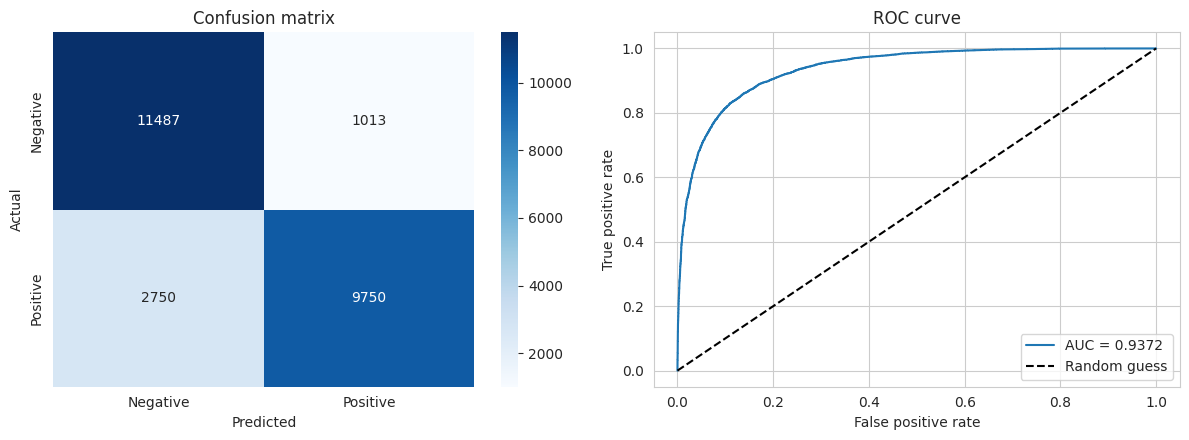

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Negative", "Positive"], yticklabels=["Negative", "Positive"])
axes[0].set_title("Confusion matrix"); axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual")

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)
axes[1].plot(fpr, tpr, label=f"AUC = {auc:.4f}")
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[1].set_title("ROC curve"); axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].legend()

plt.tight_layout()
plt.show()

## 9. Error Analysis

Metrics tell us *how often* the model is wrong; looking at actual mistakes tells us *why*. Below we print a few reviews the model misclassified with high confidence. Typical causes are sarcasm, mixed opinions ("great acting but a terrible plot"), and reviews truncated at `max_len`.

In [13]:
# Use the original (unpadded) test reviews for readable text
(_, _), (x_test_raw, _) = imdb.load_data(num_words=CONFIG["vocab_size"])

wrong_idx = np.where(y_pred != y_test)[0]
# Most confident mistakes: probability far from the true label
confidence_error = np.abs(y_prob[wrong_idx] - y_test[wrong_idx])
worst = wrong_idx[np.argsort(-confidence_error)[:5]]

for i in worst:
    actual = "Positive" if y_test[i] == 1 else "Negative"
    pred = "Positive" if y_pred[i] == 1 else "Negative"
    print(f"Actual: {actual} | Predicted: {pred} | P(positive) = {y_prob[i]:.3f}")
    print(decode_review(x_test_raw[i])[:350], "...\n")

Actual: Negative | Predicted: Positive | P(positive) = 0.999
<START> this movie was pure genius john waters is brilliant it is hilarious and i am not sick of it even after seeing it about 20 times since i bought it a few months ago the acting is great although <UNK> lake could have been better and johnny <UNK> is magnificent he is such a beautiful man and a very talented actor and seeing most of <UNK> movies ...

Actual: Negative | Predicted: Positive | P(positive) = 0.999
<START> this is without a doubt the most hilarious movie i've ever seen seriously if the makers of this movie are ever discovered they'll put guys like jim carrey out of a job rent jack o tonight believe me you won't regret it ...

Actual: Negative | Predicted: Positive | P(positive) = 0.998
<START> masterpiece <UNK> top blows the screen away never has one movie captured the essence of the human spirit quite like <UNK> of the board 10 10 don't miss this instant classic ...

Actual: Positive | Predicted: Negative | P(

## 10. Predicting on Custom Reviews

To use the model on new text we must apply **exactly the same preprocessing** as in training:

1. Lowercase and remove punctuation
2. Map each word to its index (words outside the vocabulary → `<UNK>`)
3. Prepend the `<START>` token
4. Pad / truncate to `max_len`

In [14]:
def encode_text(text, cfg=CONFIG):
    text = re.sub(r"[^a-z0-9\s']", " ", text.lower())
    tokens = text.split()
    seq = [1]  # <START>
    for w in tokens:
        idx = word_index.get(w, 2)           # unknown -> <UNK>
        seq.append(idx if idx < cfg["vocab_size"] else 2)
    return pad_sequences([seq], maxlen=cfg["max_len"], padding="post", truncating="post")

def predict_sentiment(text, model=model):
    prob = float(model.predict(encode_text(text), verbose=0)[0][0])
    label = "Positive" if prob >= 0.5 else "Negative"
    confidence = prob if prob >= 0.5 else 1 - prob
    return label, confidence

samples = [
    "An absolute masterpiece. The acting was brilliant and the story kept me hooked till the end.",
    "Terrible movie. The plot made no sense and I wasted two hours of my life.",
    "The visuals were stunning, but the script was weak and the ending felt rushed.",
    "I loved the characters, but I really didn't enjoy the pacing.",
]
for s in samples:
    label, conf = predict_sentiment(s)
    print(f"{label:8s} ({conf:.1%})  <-  {s}")

Positive (99.4%)  <-  An absolute masterpiece. The acting was brilliant and the story kept me hooked till the end.
Negative (96.9%)  <-  Terrible movie. The plot made no sense and I wasted two hours of my life.
Negative (83.4%)  <-  The visuals were stunning, but the script was weak and the ending felt rushed.
Positive (92.5%)  <-  I loved the characters, but I really didn't enjoy the pacing.


## 11. Saving the Model

The best model was already saved by `ModelCheckpoint`. We also save the final model and show how to reload it for later use (e.g., in a web app).

In [15]:
model.save("models/lstm_sentiment_final.keras")

reloaded = keras.models.load_model("models/lstm_sentiment_final.keras")
print("Reloaded model test accuracy:", round(reloaded.evaluate(x_test, y_test, verbose=0)[1], 4))

Reloaded model test accuracy: 0.8495


## 12. Conclusion and Future Work

### Summary
- Loaded and explored the IMDB dataset (50,000 balanced reviews).
- Preprocessed text via integer encoding, padding and a stratified validation split.
- Built a **Bidirectional LSTM** classifier in TensorFlow/Keras with dropout regularisation.
- Trained with early stopping, checkpointing and learning-rate scheduling.
- Evaluated with accuracy, precision/recall/F1, confusion matrix and ROC-AUC, and inspected errors.

### Limitations
- Vocabulary limited to 10,000 words; rare words become `<UNK>`.
- Reviews longer than `max_len` are truncated.
- Mixed-sentiment text and sarcasm remain hard.

### Possible Improvements
1. Use **pre-trained embeddings** (GloVe, Word2Vec) instead of learning from scratch.
2. **Stack** multiple LSTM layers or try **GRU**.
3. Add an **attention** mechanism, or fine-tune a **Transformer** such as BERT for higher accuracy.
4. Tune hyperparameters (`max_len`, `lstm_units`, `dropout`, learning rate) using Keras Tuner.
5. Apply data augmentation (back-translation, synonym replacement).

### References
- Maas et al. (2011). *Learning Word Vectors for Sentiment Analysis*. ACL.
- Hochreiter & Schmidhuber (1997). *Long Short-Term Memory*. Neural Computation.
- TensorFlow/Keras documentation: https://www.tensorflow.org/api_docs